Размерность таблицы X_bp (базовые свойства): (1023, 10)
Размерность таблицы X_nup (параметры нашивки): (1040, 3)
Размерность объединенного датасета (INNER): (1023, 13)

Количество пропусков по признакам:
Соотношение матрица-наполнитель         0
Плотность, кг/м3                        0
модуль упругости, ГПа                   0
Количество отвердителя, м.%             0
Содержание эпоксидных групп,%_2         0
Температура вспышки, С_2                0
Поверхностная плотность, г/м2           0
Модуль упругости при растяжении, ГПа    0
Прочность при растяжении, МПа           0
Потребление смолы, г/м2                 0
Угол нашивки, град                      0
Шаг нашивки                             0
Плотность нашивки                       0
dtype: int64


,mean,median,min,max,std
Соотношение матрица-наполнитель,2.9304,2.9069,0.3894,5.5917,0.9132
"Плотность, кг/м3",1975.7349,1977.6217,1731.7646,2207.7735,73.7292
"модуль упругости, ГПа",739.9232,739.6643,2.4369,1911.5365,330.2316
"Количество отвердителя, м.%",110.5708,110.5648,17.7403,198.9532,28.2959
"Содержание эпоксидных групп,%_2",22.2444,22.2307,14.2550,33.0000,2.4063
"Температура вспышки, С_2",285.8822,285.8968,100.0000,413.2734,40.9433
"Поверхностная плотность, г/м2",482.7318,451.8644,0.6037,1399.5424,281.3147
"Модуль упругости при растяжении, ГПа",73.3286,73.2688,64.0541,82.6821,3.1190
"Прочность при растяжении, МПа",2466.9228,2459.5245,1036.8566,3848.4367,485.6280
"Потребление смолы, г/м2",218.4231,219.1989,33.8030,414.5906,59.7359


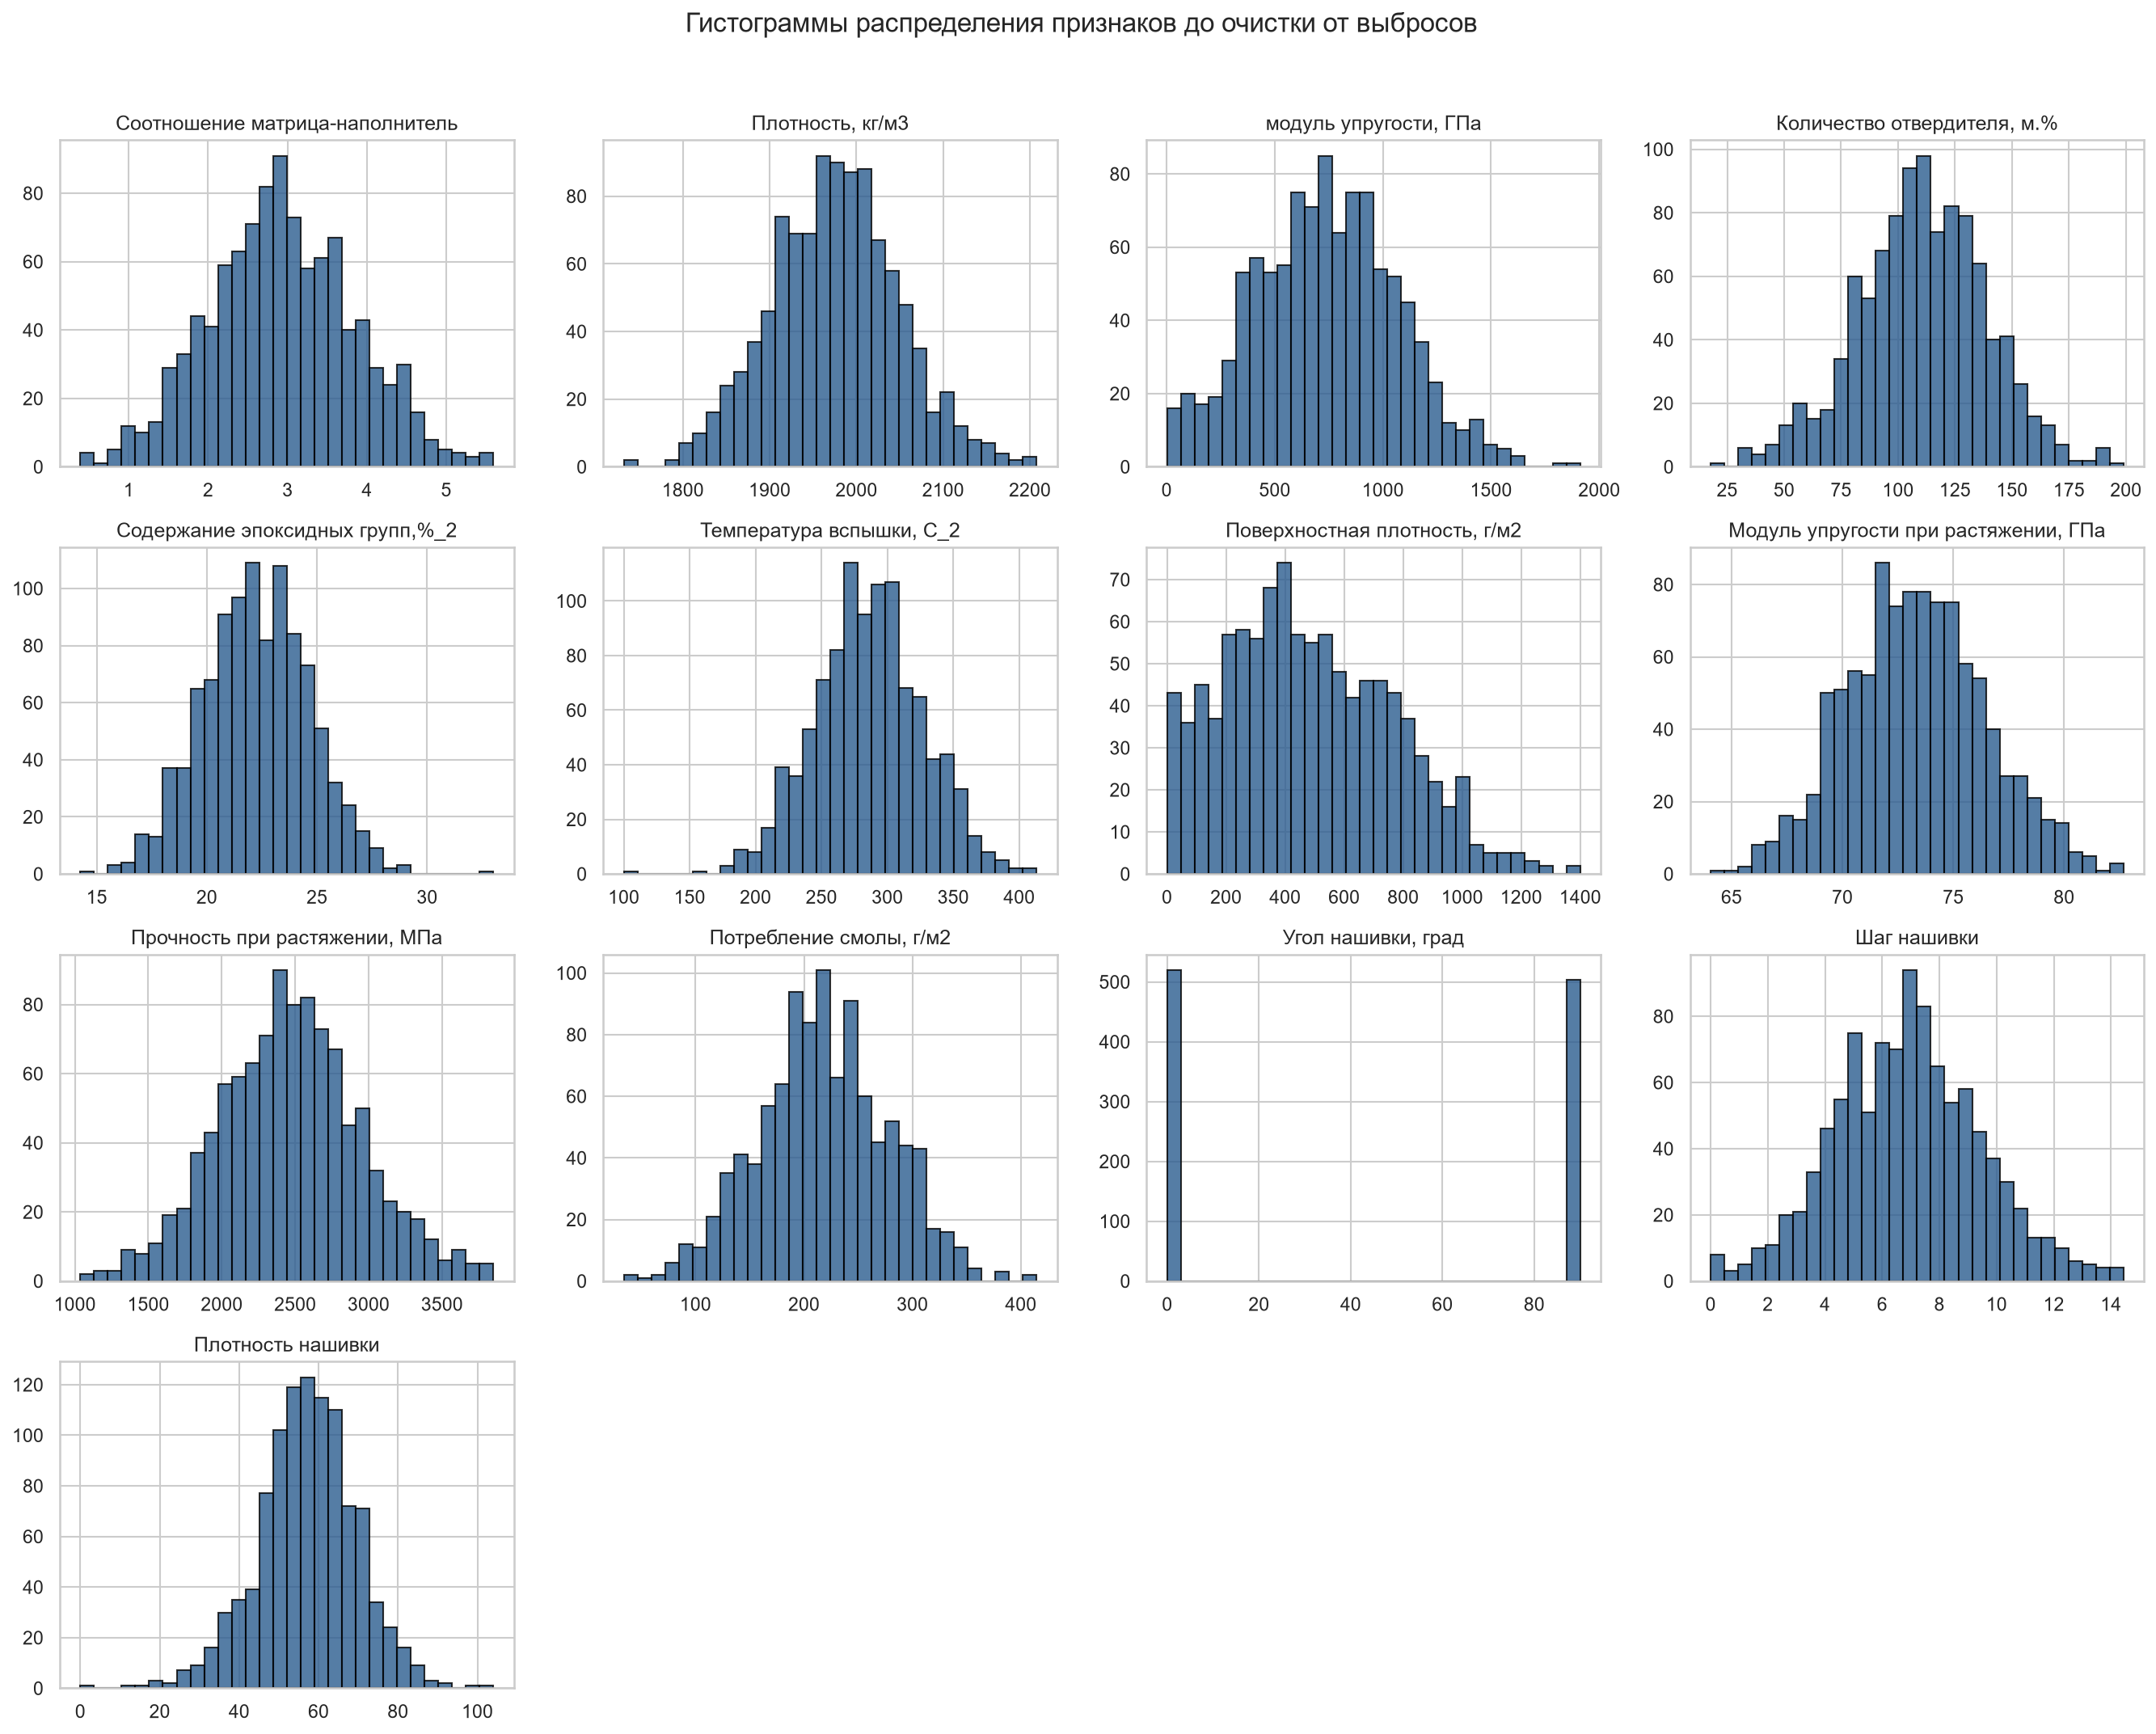

In [2]:
# ==============================================================================
# ЭТАП 1. ЗАГРУЗКА ИСХОДНЫХ ДАННЫХ, ОБЪЕДИНЕНИЕ И ПЕРВИЧНЫЙ СТАТИСТИЧЕСКИЙ АНАЛИЗ
# Цель: загрузить таблицы характеристик связующего (X_bp) и параметров нашивки (X_nup),
# объединить их по индексу (INNER JOIN), проверить пропуски и оценить базовые статистики.
# ==============================================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Создаем директорию для автоматического сохранения графиков в высоком качестве
# (используются в пояснительной записке и презентации)
os.makedirs('../docs/images', exist_ok=True)

# Задаем единый стиль и высокое разрешение (150 DPI) для всех графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 150

# 1. Загрузка исходных файлов Excel (первый столбец используем как индекс образца)
df_bp = pd.read_excel('../data/X_bp.xlsx', index_col=0)
df_nup = pd.read_excel('../data/X_nup.xlsx', index_col=0)

print(f"Размерность таблицы X_bp (базовые свойства): {df_bp.shape}")
print(f"Размерность таблицы X_nup (параметры нашивки): {df_nup.shape}")

# 2. Объединение таблиц по индексу методом INNER JOIN
# Оставляем только те образцы, для которых есть записи в обеих таблицах
df = df_bp.join(df_nup, how='inner')
print(f"Размерность объединенного датасета (INNER): {df.shape}\n")

# 3. Проверка наличия пропущенных значений (NaN) в каждом столбце
missing_values = df.isnull().sum()
print("Количество пропусков по признакам:")
print(missing_values)

# 4. Расчет описательных статистик (среднее, медиана, минимум, максимум, ст. отклонение)
stats = df.describe().T[['mean', '50%', 'min', 'max', 'std']]
stats = stats.rename(columns={'50%': 'median'})  # Переименовываем 50-й перцентиль в медиану
display(stats.round(4))

# Сохраняем таблицу статистик до очистки в Excel для вставки в пояснительную записку
stats.round(4).to_excel('../docs/eda_stats_before.xlsx')

# 5. Построение гистограмм распределения для всех 13 признаков
# Позволяет визуально оценить вид распределения (нормальное, скошенное, бимодальное)
axes = df.hist(bins=30, figsize=(18, 14), color='#2b5c8f', edgecolor='black', alpha=0.8)
plt.suptitle('Гистограммы распределения признаков до очистки от выбросов', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('../docs/images/01_histograms_before.png', bbox_inches='tight')
plt.show()


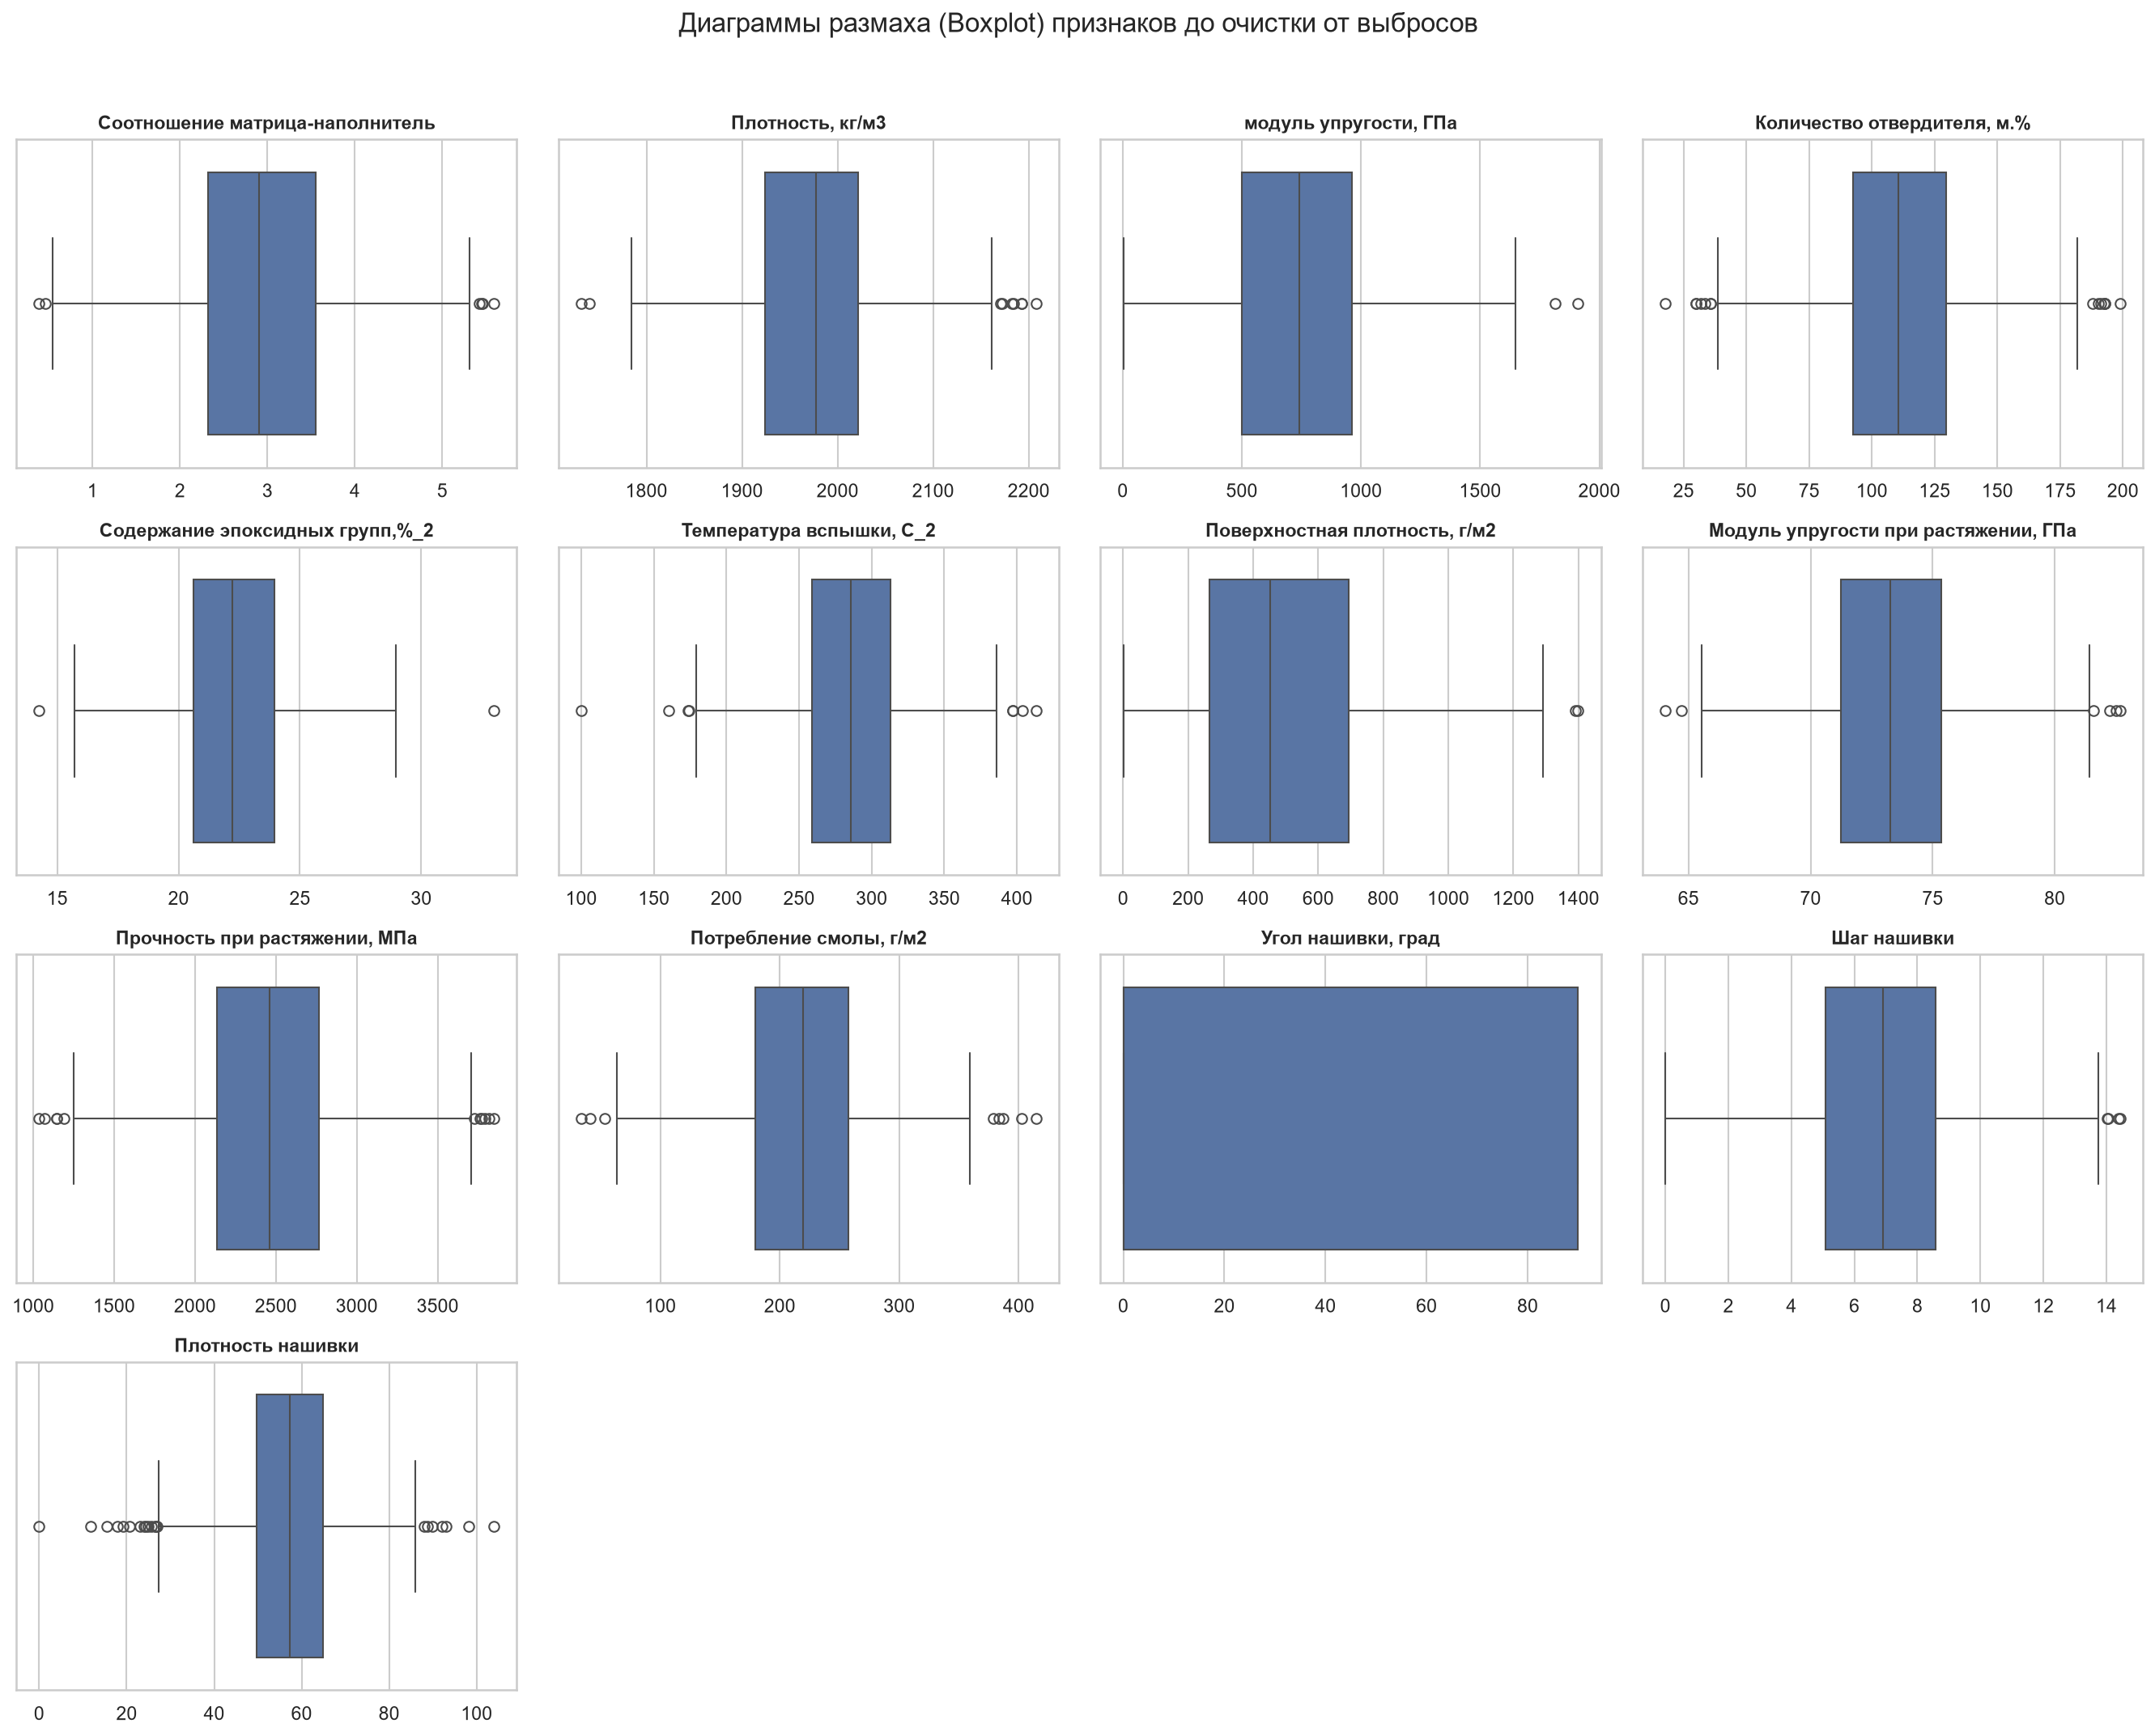

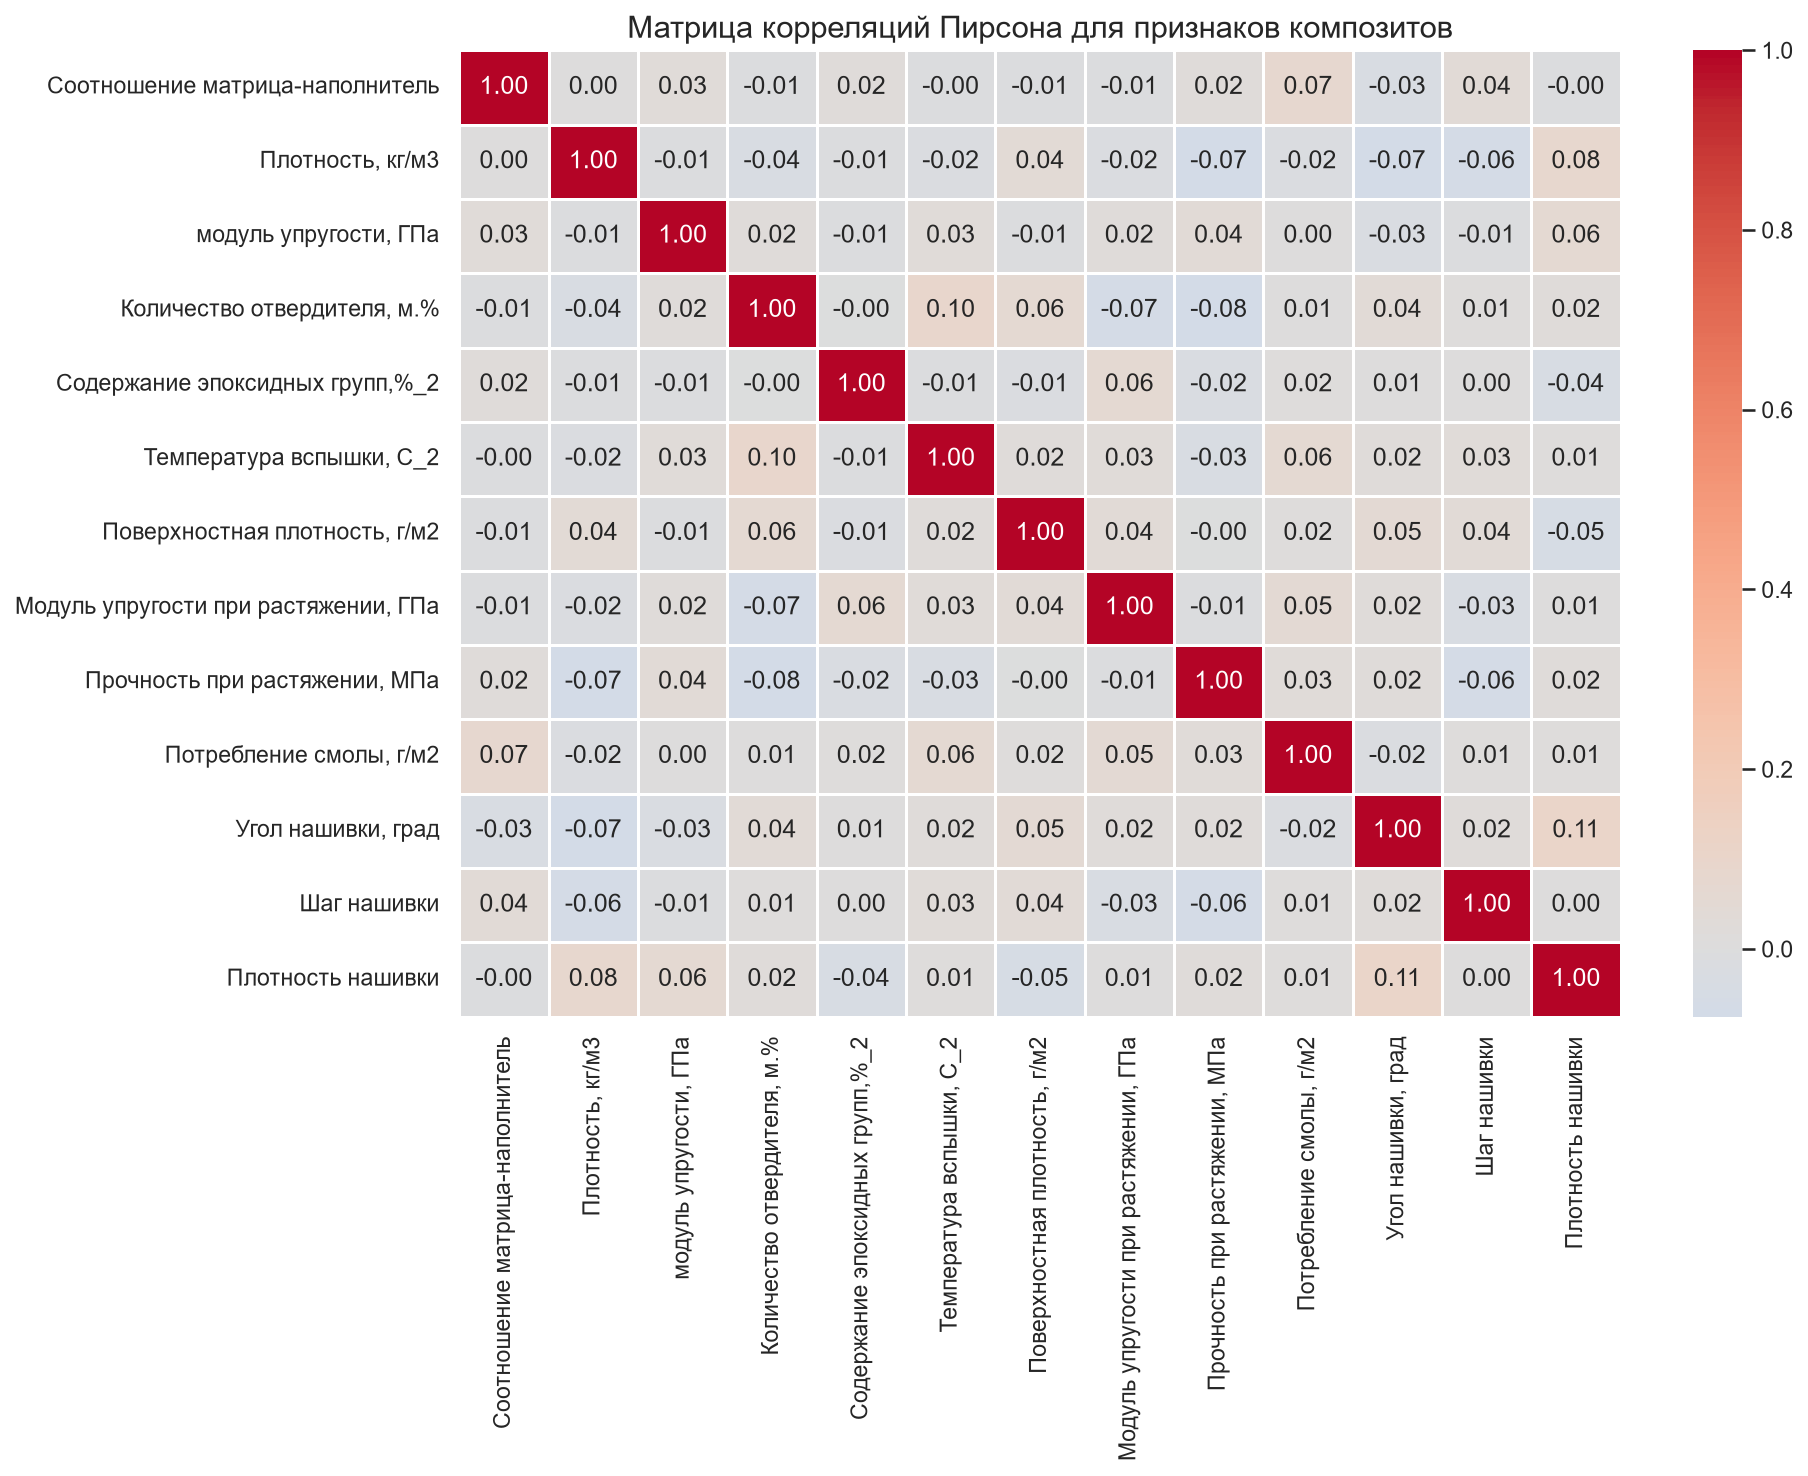

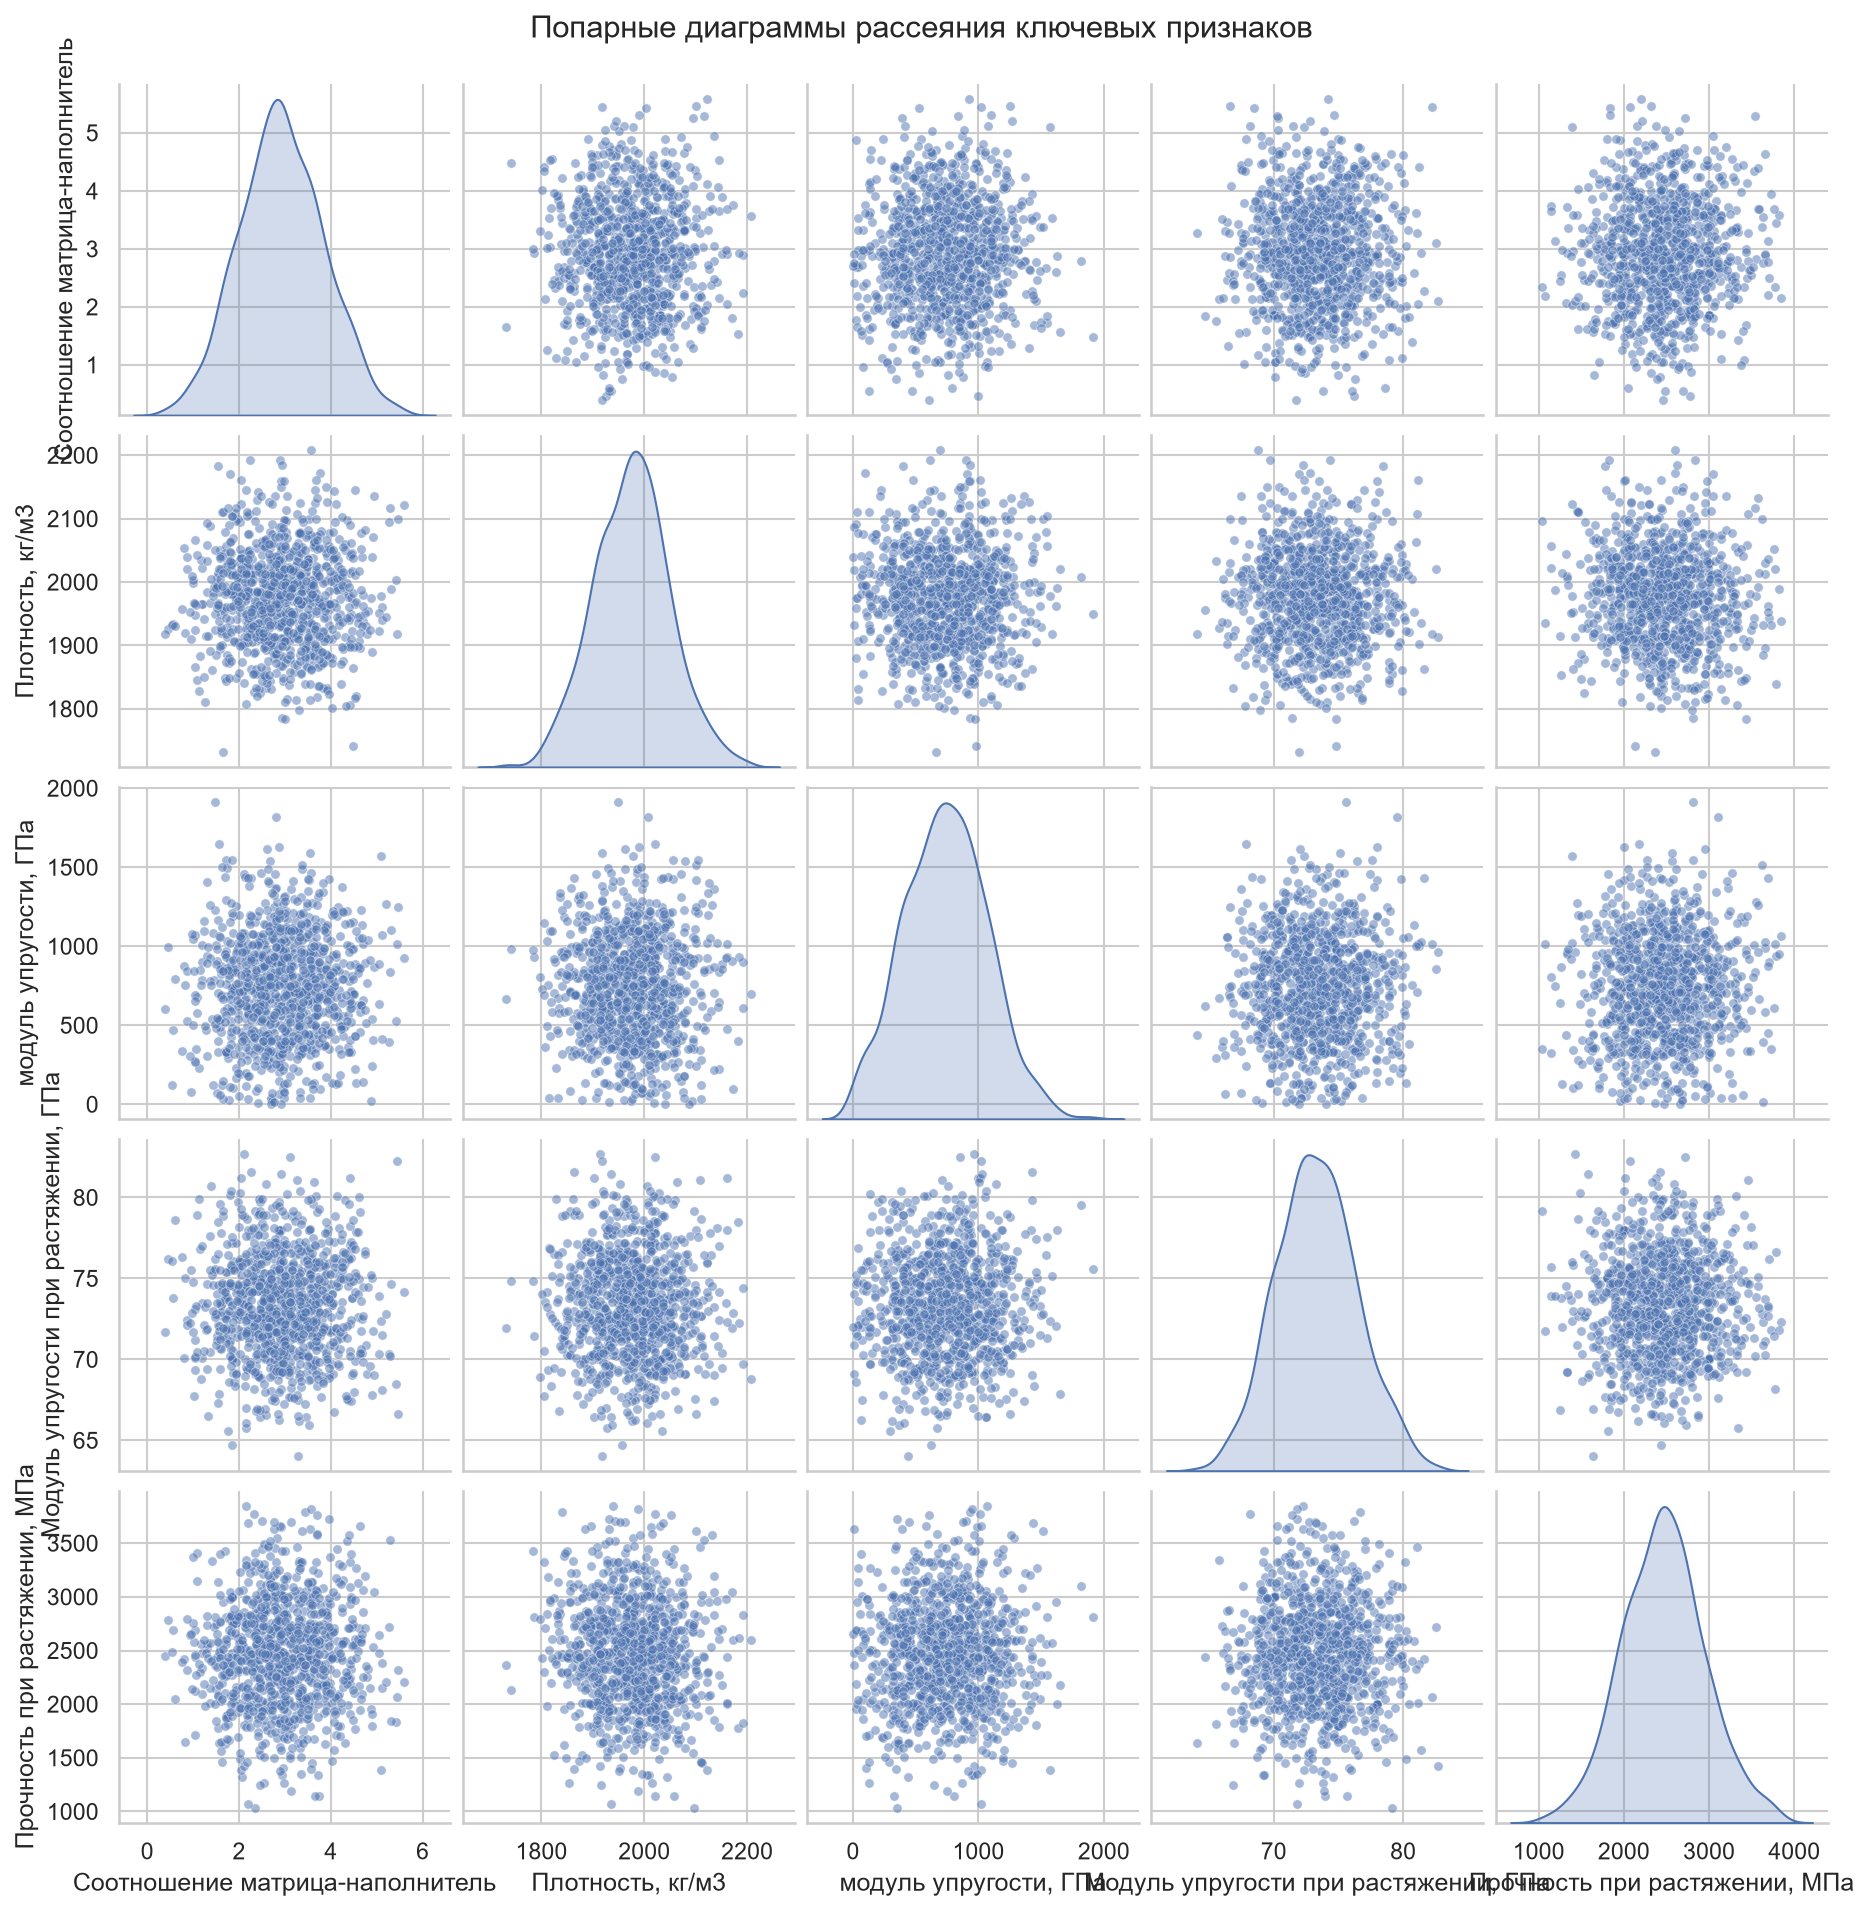

In [3]:
# ==============================================================================
# ЭТАП 2. ВИЗУАЛЬНЫЙ РАЗВЕДОЧНЫЙ АНАЛИЗ ДАННЫХ (EDA)
# Цель: оценить форму распределений, выявить выбросы и проверить наличие
# линейных взаимосвязей (корреляций) между входными и целевыми переменными.
# ==============================================================================

# 1. Построение диаграмм размаха ("ящик с усами" / Boxplot)
# Используем сетку 4x4, чтобы каждый признак отображался в собственном масштабе
# и аномальные выбросы (точки за пределами усов 1.5*IQR) были хорошо видны.
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(18, 14))
axes = axes.flatten()  # Преобразуем двумерный массив осей в одномерный для цикла

for i, col in enumerate(df.columns):
    sns.boxplot(x=df[col], ax=axes[i], color='#4c72b0')
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')  # Убираем дублирующую подпись оси X для чистоты графика

# Удаляем 3 пустые ячейки сетки (так как всего признаков 13, а ячеек 16)
for j in range(len(df.columns), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Диаграммы размаха (Boxplot) признаков до очистки от выбросов', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('../docs/images/02_boxplots_before.png', bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------------------
# 2. Построение матрицы линейных корреляций Пирсона (Heatmap)
# Проверяем, есть ли сильная линейная зависимость между признаками (мультиколлинеарность),
# а также оцениваем линейную связь факторов с целевыми переменными.
plt.figure(figsize=(13, 10))
corr_matrix = df.corr(method='pearson')

sns.heatmap(
    corr_matrix,
    annot=True,          # Выводим числовые значения коэффициентов корреляции в ячейках
    fmt='.2f',           # Округляем до 2 знаков после запятой
    cmap='coolwarm',     # Цветовая шкала: синий (отрицательная), красный (положительная)
    center=0,            # Центрируем цветовую шкалу на нуле
    linewidths=0.5       # Добавляем тонкие границы между ячейками
)
plt.title('Матрица корреляций Пирсона для признаков композитов', fontsize=15)
plt.tight_layout()
plt.savefig('../docs/images/03_correlation_matrix.png', bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------------------
# 3. Построение попарных диаграмм рассеяния (Pairplot)
# Для наглядности и читаемости берем ключевые физико-механические параметры
# и целевые переменные. На диагонали строим ядерную оценку плотности (KDE).
key_cols = [
    'Соотношение матрица-наполнитель',
    'Плотность, кг/м3',
    'модуль упругости, ГПа',
    'Модуль упругости при растяжении, ГПа',
    'Прочность при растяжении, МПа'
]

pair_plot = sns.pairplot(
    df[key_cols],
    diag_kind='kde',                     # Сглаженная кривая плотности на диагонали
    plot_kws={'alpha': 0.5, 's': 20}     # Полупрозрачность точек для оценки их скопления
)
pair_plot.fig.suptitle('Попарные диаграммы рассеяния ключевых признаков', y=1.02, fontsize=15)
pair_plot.savefig('../docs/images/04_pairplot.png', bbox_inches='tight')
plt.show()


Количество наблюдений до очистки от выбросов: 1023
Удалено наблюдений с выбросами: 87 (8.50%)
Количество наблюдений после очистки: 936



,Min (исходный),Max (исходный),Min (после очистки IQR),Max (после очистки IQR),Min (после нормализации),Max (после нормализации)
Соотношение матрица-наполнитель,0.3894,5.5917,0.5474,5.3141,0.0,1.0
"Плотность, кг/м3",1731.7646,2207.7735,1784.4822,2161.5652,0.0,1.0
"модуль упругости, ГПа",2.4369,1911.5365,2.4369,1649.4157,0.0,1.0
"Количество отвердителя, м.%",17.7403,198.9532,38.6685,181.8284,0.0,1.0
"Содержание эпоксидных групп,%_2",14.2550,33.0000,15.6959,28.9551,0.0,1.0
"Температура вспышки, С_2",100.0000,413.2734,179.3744,386.0680,0.0,1.0
"Поверхностная плотность, г/м2",0.6037,1399.5424,0.6037,1291.3401,0.0,1.0
"Модуль упругости при растяжении, ГПа",64.0541,82.6821,65.5533,81.4171,0.0,1.0
"Прочность при растяжении, МПа",1036.8566,3848.4367,1250.3928,3705.6725,0.0,1.0
"Потребление смолы, г/м2",33.8030,414.5906,63.6857,359.0522,0.0,1.0


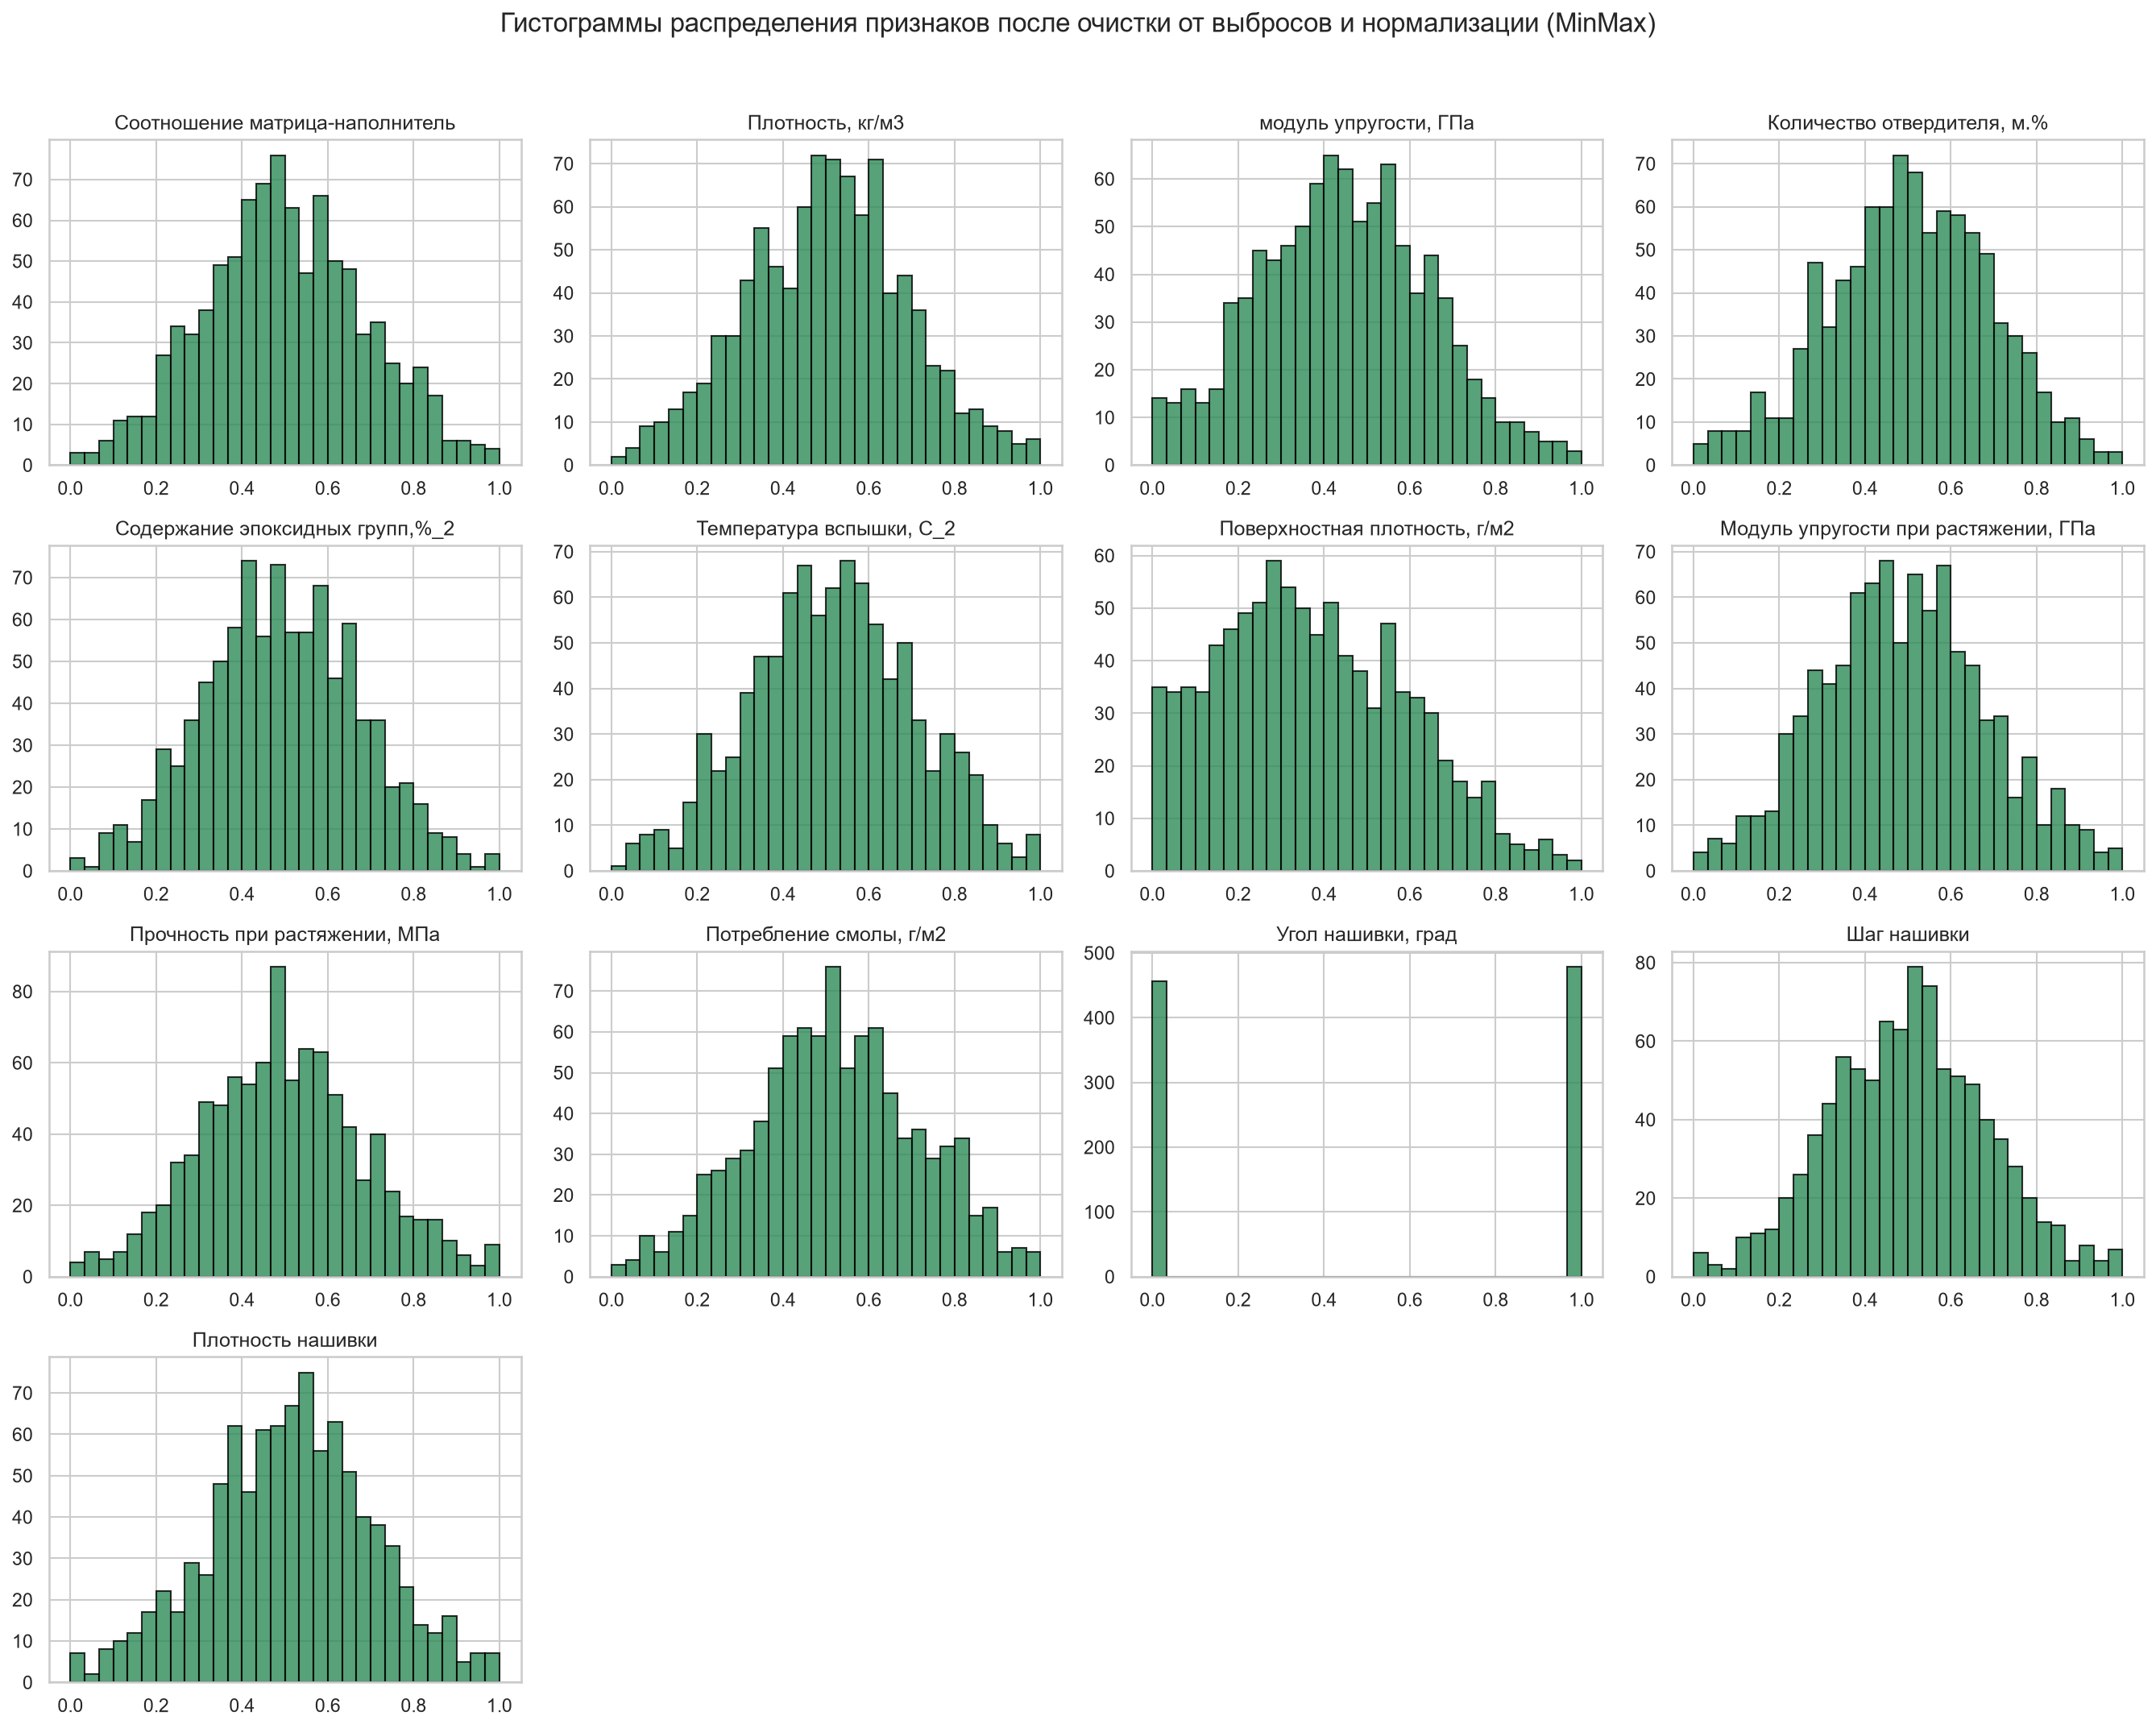

Очищенные датасеты и MinMaxScaler успешно сохранены.


In [4]:
# ==============================================================================
# ЭТАП 3. ПРЕДОБРАБОТКА ДАННЫХ: ИСКЛЮЧЕНИЕ ВЫБРОСОВ И НОРМАЛИЗАЦИЯ
# Цель: удалить аномальные наблюдения (выбросы) методом межквартильного размаха (IQR),
# привести все признаки к единому масштабу [0, 1] с помощью MinMaxScaler
# и сохранить графики распределений до и после нормализации (для Раздела 2.1 ВКР).
# ==============================================================================

import joblib
from sklearn.preprocessing import MinMaxScaler

# 1. Выявление и исключение статистических выбросов методом межквартильного размаха (IQR)
# Границы допустимых значений определяются как [Q1 - 1.5 * IQR; Q3 + 1.5 * IQR]
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1

# Формируем булеву маску: оставляем только те строки, где ни один признак не выходит за границы
outlier_mask = ((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).any(axis=1)
df_clean = df[~outlier_mask].copy()

print(f"Количество наблюдений до очистки от выбросов: {len(df)}")
print(f"Удалено наблюдений с выбросами: {outlier_mask.sum()} ({outlier_mask.mean()*100:.2f}%)")
print(f"Количество наблюдений после очистки: {len(df_clean)}\n")

# 2. Нормализация данных (масштабирование в диапазон)
# MinMaxScaler сохраняет форму исходного распределения, но устраняет разницу в размерностях
# (например, плотность ~2000 кг/м3 и шаг нашивки ~7 мм), что критично для нейросетей и линейных моделей.
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_clean),
    columns=df_clean.columns,
    index=df_clean.index
)

# 3. Формирование сводной таблицы минимальных и максимальных значений
# (требуется по заданию для Раздела 2.1 пояснительной записки)
minmax_summary = pd.DataFrame({
    'Min (исходный)': df.min(),
    'Max (исходный)': df.max(),
    'Min (после очистки IQR)': df_clean.min(),
    'Max (после очистки IQR)': df_clean.max(),
    'Min (после нормализации)': df_scaled.min(),
    'Max (после нормализации)': df_scaled.max()
})
display(minmax_summary.round(4))
minmax_summary.round(4).to_excel('../docs/preprocessing_minmax.xlsx')

# 4. Построение гистограмм распределения признаков ПОСЛЕ очистки и нормализации
axes = df_scaled.hist(bins=30, figsize=(18, 14), color='#2e8b57', edgecolor='black', alpha=0.8)
plt.suptitle('Гистограммы распределения признаков после очистки от выбросов и нормализации (MinMax)', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('../docs/images/05_histograms_after_scaling.png', bbox_inches='tight')
plt.show()

# 5. Сохранение предобработанных данных и скейлера для следующих этапов и веб-приложения
os.makedirs('../models', exist_ok=True)
df_clean.to_csv('../data/df_clean.csv')
df_scaled.to_csv('../data/df_scaled.csv')
joblib.dump(scaler, '../models/minmax_scaler.pkl')
print("Очищенные датасеты и MinMaxScaler успешно сохранены.")


In [5]:
# ==============================================================================
# ЭТАП 4. РАЗРАБОТКА, ОБУЧЕНИЕ И ТЕСТИРОВАНИЕ МОДЕЛЕЙ МАШИННОГО ОБУЧЕНИЯ (ЗАДАНИЕ 1)
# Цель: обучить 5 алгоритмов регрессии для прогнозирования:
#   1) Модуля упругости при растяжении, ГПа
#   2) Прочности при растяжении, МПа
# Разделение выборки: 70% обучение (train), 30% тестирование (test).
# ==============================================================================

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Формируем матрицу входных признаков (X) и целевые переменные (y1, y2)
# Входные признаки берем из нормализованного датасета (df_scaled),
# а целевые переменные — из очищенного в реальных физических единицах (ГПа и МПа).
target_cols = ['Модуль упругости при растяжении, ГПа', 'Прочность при растяжении, МПа']
X = df_scaled.drop(columns=target_cols)
y_modulus = df_clean['Модуль упругости при растяжении, ГПа']
y_strength = df_clean['Прочность при растяжении, МПа']

# Сохраняем список входных колонок для веб-приложения
joblib.dump(list(X.columns), '../models/ml_features.pkl')

# 2. Разделение данных на обучающую (70%) и тестовую (30%) выборки (по условию ВКР)
X_train, X_test, y_mod_train, y_mod_test, y_str_train, y_str_test = train_test_split(
    X, y_modulus, y_strength, test_size=0.30, random_state=42
)
print(f"Размер обучающей выборки (70%): {X_train.shape}")
print(f"Размер тестовой выборки (30%):  {X_test.shape}\n")

# 3. Функция для обучения набора моделей, расчета метрик (Train/Test) и выбора лучшей
def evaluate_models(X_tr, X_te, y_tr, y_te, target_name):
    # Список сравниваемых алгоритмов (от простых линейных до ансамблей)
    models = {
        'Linear Regression': LinearRegression(),
        'Ridge Regression': Ridge(alpha=1.0),
        'KNN Regressor': KNeighborsRegressor(n_neighbors=7),
        'SVR (RBF)': SVR(kernel='rbf', C=10.0),
        'Random Forest': RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42),
        'Gradient Boosting': GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42)
    }
    
    results = []
    best_model = None
    best_r2 = -np.inf
    best_name = ""
    
    for name, model in models.items():
        # Обучение модели на тренировочной выборке
        model.fit(X_tr, y_tr)
        
        # Прогноз на тренировочной и тестовой выборках
        pred_tr = model.predict(X_tr)
        pred_te = model.predict(X_te)
        
        # Расчет метрик качества (MAE, RMSE, R2)
        mae_tr = mean_absolute_error(y_tr, pred_tr)
        rmse_tr = np.sqrt(mean_squared_error(y_tr, pred_tr))
        r2_tr = r2_score(y_tr, pred_tr)
        
        mae_te = mean_absolute_error(y_te, pred_te)
        rmse_te = np.sqrt(mean_squared_error(y_te, pred_te))
        r2_te = r2_score(y_te, pred_te)
        
        results.append({
            'Модель': name,
            'Train MAE': mae_tr,
            'Test MAE': mae_te,
            'Train RMSE': rmse_tr,
            'Test RMSE': rmse_te,
            'Train R2': r2_tr,
            'Test R2': r2_te
        })
        
        # Отслеживаем лучшую модель по минимальной ошибке MAE на тестовой выборке
        if best_model is None or mae_te < min([r['Test MAE'] for r in results[:-1]]):
            best_model = model
            best_name = name
            
    results_df = pd.DataFrame(results).round(4)
    print(f"=== Результаты прогнозирования: {target_name} ===")
    display(results_df)
    print(f"Лучшая модель по Test MAE: {best_name}\n")
    return results_df, best_model, best_name

# 4. Запускаем обучение и оценку для обеих целевых переменных
res_modulus, best_mod_model, best_mod_name = evaluate_models(
    X_train, X_test, y_mod_train, y_mod_test, 'Модуль упругости при растяжении, ГПа'
)
res_strength, best_str_model, best_str_name = evaluate_models(
    X_train, X_test, y_str_train, y_str_test, 'Прочность при растяжении, МПа'
)

# 5. Сохраняем таблицы метрик в Excel (для Раздела 2.3 записки) и лучшие модели на диск
res_modulus.to_excel('../docs/metrics_modulus.xlsx', index=False)
res_strength.to_excel('../docs/metrics_strength.xlsx', index=False)

joblib.dump(best_mod_model, '../models/best_model_modulus.pkl')
joblib.dump(best_str_model, '../models/best_model_strength.pkl')
print("Таблицы метрик и лучшие ML-модели успешно сохранены!")


Размер обучающей выборки (70%): (655, 11)
Размер тестовой выборки (30%):  (281, 11)

=== Результаты прогнозирования: Модуль упругости при растяжении, ГПа ===


,Модель,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Linear Regression,2.4525,2.4160,3.0459,2.9573,0.0146,-0.0036
1,Ridge Regression,2.4527,2.4149,3.0460,2.9565,0.0146,-0.0031
2,KNN Regressor,2.2964,2.6208,2.8864,3.2199,0.1152,-0.1897
3,SVR (RBF),1.5462,2.6561,2.3590,3.2697,0.4090,-0.2269
4,Random Forest,1.4559,2.4197,1.7767,2.9757,0.6647,-0.0161
5,Gradient Boosting,1.6464,2.4546,2.0635,3.0494,0.5478,-0.0671


Лучшая модель по Test MAE: Ridge Regression

=== Результаты прогнозирования: Прочность при растяжении, МПа ===


,Модель,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Linear Regression,368.3987,362.8546,460.8162,461.9324,0.0247,-0.0454
1,Ridge Regression,368.4390,362.5063,460.8277,461.5472,0.0247,-0.0437
2,KNN Regressor,342.0067,381.7221,426.4997,492.1626,0.1646,-0.1868
3,SVR (RBF),366.3021,364.1813,461.9822,461.3186,0.0198,-0.0427
4,Random Forest,209.3127,374.3774,254.4885,466.2784,0.7026,-0.0652
5,Gradient Boosting,230.2544,389.4820,288.1279,483.4829,0.6187,-0.1453


Лучшая модель по Test MAE: Ridge Regression

Таблицы метрик и лучшие ML-модели успешно сохранены!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │             832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,457 (13.50 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 0 (0.00 B)


=== Метрики нейронной сети (Соотношение матрица-наполнитель) ===
Train MAE: 0.7260
Test MAE: 0.7238
Train RMSE: 0.9040
Test RMSE: 0.9159
Train R2: -0.0052
Test R2: -0.1014


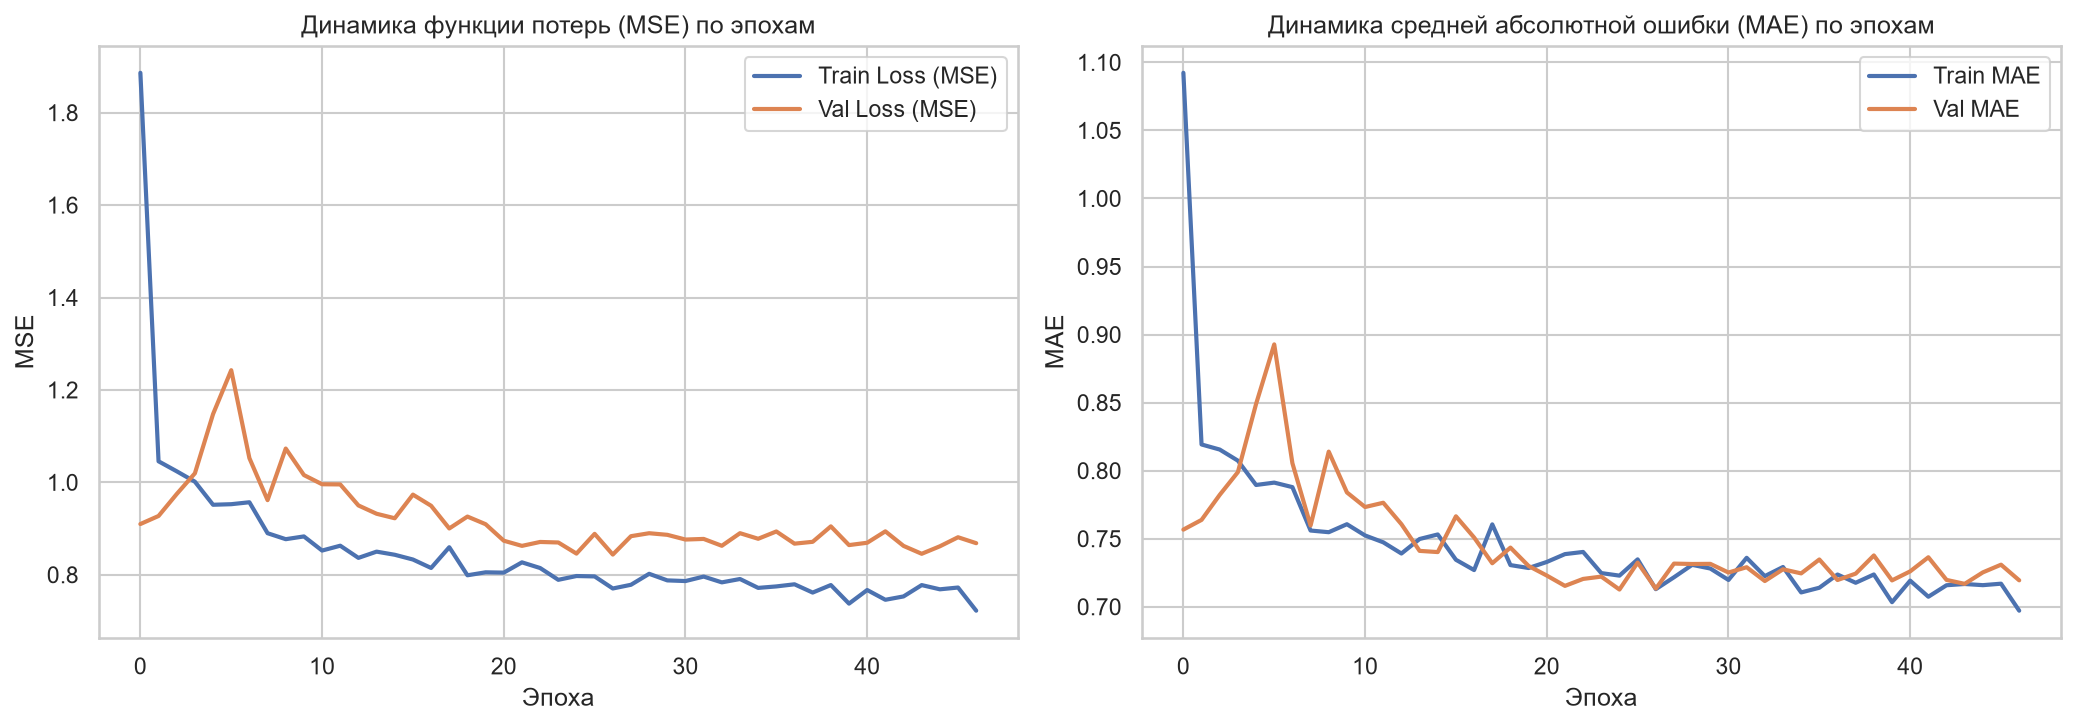

Нейронная сеть успешно сохранена в models/nn_matrix_filler.keras


In [6]:
# ==============================================================================
# ЭТАП 5. РАЗРАБОТКА И ОБУЧЕНИЕ НЕЙРОННОЙ СЕТИ (ЗАДАНИЕ 2)
# Цель: построить нейронную сеть (многослойный перцептрон) для рекомендации
# параметра "Соотношение матрица-наполнитель" на основе 12 остальных признаков.
# ==============================================================================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

# Фиксируем зерно случайности для воспроизводимости результатов нейросети
tf.random.set_seed(42)

# 1. Подготовка данных для нейронной сети
# Целевая переменная — "Соотношение матрица-наполнитель" (в исходных единицах),
# входные признаки — все остальные 12 нормализованных параметров.
target_nn = 'Соотношение матрица-наполнитель'
X_nn = df_scaled.drop(columns=[target_nn])
y_nn = df_clean[target_nn]

# Сохраняем список входных признаков для нейронной сети (понадобится в веб-приложении)
joblib.dump(list(X_nn.columns), '../models/nn_features.pkl')

# Разделение на обучающую (70%) и тестовую (30%) выборки
X_nn_train, X_nn_test, y_nn_train, y_nn_test = train_test_split(
    X_nn, y_nn, test_size=0.30, random_state=42
)

# 2. Проектирование архитектуры полносвязной нейронной сети (MLP)
# Используем слои Dropout и L2-регуляризацию для предотвращения переобучения
model_nn = Sequential([
    Input(shape=(X_nn_train.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.1),
    Dense(16, activation='relu'),
    Dense(1, activation='linear')  # Линейная активация на выходе для задачи регрессии
])

# Компиляция модели: оптимизатор Adam, функция потерь MSE, метрика контроля MAE
model_nn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
    loss='mse',
    metrics=['mae']
)

model_nn.summary()

# Настраиваем раннюю остановку (EarlyStopping), чтобы остановить обучение при выходе на плато
early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

# 3. Обучение нейронной сети (20% от train выделяем на валидацию)
history = model_nn.fit(
    X_nn_train, y_nn_train,
    validation_split=0.20,
    epochs=150,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0
)

# 4. Оценка качества нейронной сети на тренировочной и тестовой выборках
pred_nn_train = model_nn.predict(X_nn_train, verbose=0).flatten()
pred_nn_test = model_nn.predict(X_nn_test, verbose=0).flatten()

nn_metrics = {
    'Train MAE': mean_absolute_error(y_nn_train, pred_nn_train),
    'Test MAE': mean_absolute_error(y_nn_test, pred_nn_test),
    'Train RMSE': np.sqrt(mean_squared_error(y_nn_train, pred_nn_train)),
    'Test RMSE': np.sqrt(mean_squared_error(y_nn_test, pred_nn_test)),
    'Train R2': r2_score(y_nn_train, pred_nn_train),
    'Test R2': r2_score(y_nn_test, pred_nn_test)
}

print("\n=== Метрики нейронной сети (Соотношение матрица-наполнитель) ===")
for k, v in nn_metrics.items():
    print(f"{k}: {v:.4f}")

# 5. Построение графиков процесса обучения (Loss и MAE по эпохам) для Раздела 2.4 ВКР
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train Loss (MSE)', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Val Loss (MSE)', linewidth=2)
axes[0].set_title('Динамика функции потерь (MSE) по эпохам')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('MSE')
axes[0].legend()

axes[1].plot(history.history['mae'], label='Train MAE', linewidth=2)
axes[1].plot(history.history['val_mae'], label='Val MAE', linewidth=2)
axes[1].set_title('Динамика средней абсолютной ошибки (MAE) по эпохам')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('MAE')
axes[1].legend()

plt.tight_layout()
plt.savefig('../docs/images/06_nn_training_history.png', bbox_inches='tight')
plt.show()

# 6. Сохранение обученной нейронной сети в папку models
model_nn.save('../models/nn_matrix_filler.keras')
print("Нейронная сеть успешно сохранена в models/nn_matrix_filler.keras")


In [7]:
%%writefile ../app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import tensorflow as tf

# Настройка страницы приложения
st.set_page_config(
    page_title="Прогнозирование свойств композитов",
    page_icon="🧪",
    layout="wide"
)

# Загрузка сохраненных моделей, скейлера и списков признаков (с кэшированием для скорости)
@st.cache_resource
def load_artifacts():
    scaler = joblib.load('models/minmax_scaler.pkl')
    ml_features = joblib.load('models/ml_features.pkl')
    nn_features = joblib.load('models/nn_features.pkl')
    model_modulus = joblib.load('models/best_model_modulus.pkl')
    model_strength = joblib.load('models/best_model_strength.pkl')
    model_nn = tf.keras.models.load_model('models/nn_matrix_filler.keras')
    df_clean = pd.read_csv('data/df_clean.csv', index_col=0)
    return scaler, ml_features, nn_features, model_modulus, model_strength, model_nn, df_clean

scaler, ml_features, nn_features, model_modulus, model_strength, model_nn, df_clean = load_artifacts()
all_columns = list(df_clean.columns)

# Вспомогательная функция для нормализации пользовательского ввода через обученный MinMaxScaler
def scale_input(user_dict):
    row_df = pd.DataFrame([user_dict], columns=all_columns)
    scaled_array = scaler.transform(row_df)
    return pd.DataFrame(scaled_array, columns=all_columns)

# Заголовок приложения
st.title("🧪 Прогнозирование свойств композиционных материалов")
st.markdown(
    "Интерактивная система для расчета конечных механических характеристик композита "
    "и рекомендации рецептуры на основе моделей машинного обучения и нейронных сетей "
    "*(кейс Центра НТИ МГТУ им. Н.Э. Баумана)*."
)

# Создаем две вкладки: под Задание 1 и Задание 2
tab1, tab2 = st.tabs([
    "📊 Прогноз механических свойств (ML)",
    "🧠 Рекомендация соотношения матрица-наполнитель (Нейросеть)"
])

# ==============================================================================
# ВКЛАДКА 1: ПРОГНОЗ МОДУЛЯ УПРУГОСТИ И ПРОЧНОСТИ ПРИ РАСТЯЖЕНИИ (ЗАДАНИЕ 1)
# ==============================================================================
with tab1:
    st.subheader("Введите технологические параметры композита")
    st.caption("По умолчанию подставлены средние значения из очищенной выборки.")
    
    cols = st.columns(3)
    user_input_ml = {col: float(df_clean[col].mean()) for col in all_columns}
    
    for idx, feat in enumerate(ml_features):
        min_val = float(df_clean[feat].min())
        max_val = float(df_clean[feat].max())
        mean_val = float(df_clean[feat].mean())
        
        with cols[idx % 3]:
            if feat == 'Угол нашивки, град':
                user_input_ml[feat] = float(st.selectbox(feat, options=[0.0, 90.0], index=0, key=f"ml_{feat}"))
            else:
                user_input_ml[feat] = st.number_input(
                    feat, min_value=min_val * 0.5, max_value=max_val * 1.5, value=mean_val, format="%.4f", key=f"ml_{feat}"
                )
                
    if st.button("Рассчитать механические свойства", type="primary"):
        scaled_df = scale_input(user_input_ml)
        X_input = scaled_df[ml_features]
        
        pred_mod = model_modulus.predict(X_input)
        pred_str = model_strength.predict(X_input)
        
        st.success("Расчет успешно выполнен!")
        res_col1, res_col2 = st.columns(2)
        res_col1.metric("Модуль упругости при растяжении", f"{pred_mod:.2f} ГПа")
        res_col2.metric("Прочность при растяжении", f"{pred_str:.2f} МПа")

# ==============================================================================
# ВКЛАДКА 2: РЕКОМЕНДАЦИЯ СООТНОШЕНИЯ МАТРИЦА-НАПОЛНИТЕЛЬ (ЗАДАНИЕ 2)
# ==============================================================================
with tab2:
    st.subheader("Введите целевые свойства и параметры армирования")
    st.caption("Нейронная сеть рассчитает рекомендуемое соотношение матрица-наполнитель.")
    
    cols_nn = st.columns(3)
    user_input_nn = {col: float(df_clean[col].mean()) for col in all_columns}
    
    for idx, feat in enumerate(nn_features):
        min_val = float(df_clean[feat].min())
        max_val = float(df_clean[feat].max())
        mean_val = float(df_clean[feat].mean())
        
        with cols_nn[idx % 3]:
            if feat == 'Угол нашивки, град':
                user_input_nn[feat] = float(st.selectbox(feat, options=[0.0, 90.0], index=0, key=f"nn_{feat}"))
            else:
                user_input_nn[feat] = st.number_input(
                    feat, min_value=min_val * 0.5, max_value=max_val * 1.5, value=mean_val, format="%.4f", key=f"nn_{feat}"
                )
                
    if st.button("Рекомендовать соотношение", type="primary"):
        scaled_df = scale_input(user_input_nn)
        X_input_nn = scaled_df[nn_features].values
        
        pred_ratio = model_nn.predict(X_input_nn, verbose=0).flatten()
        
        st.success("Рекомендация сформирована!")
        st.metric("Рекомендуемое соотношение матрица-наполнитель", f"{pred_ratio:.4f}")


Overwriting ../app.py


In [11]:
from sklearn.model_selection import GridSearchCV

param_grid_ridge = {'alpha': list((0.01, 0.1, 1.0, 10.0, 50.0, 100.0))}
param_grid_rf = {
    'n_estimators': list((100, 200)),
    'max_depth': list((5, 10, None)),
    'min_samples_split': list((2, 5))
}

print("=== Поиск гиперпараметров (GridSearchCV, cv=10) ===")

grid_ridge_mod = GridSearchCV(Ridge(), param_grid_ridge, cv=10, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_ridge_mod.fit(X_train, y_mod_train)

grid_rf_mod = GridSearchCV(RandomForestRegressor(random_state=42), param_grid_rf, cv=10, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_rf_mod.fit(X_train, y_mod_train)

print(f"[Модуль упругости] Лучший Ridge: {grid_ridge_mod.best_params_} | Test MAE: {mean_absolute_error(y_mod_test, grid_ridge_mod.predict(X_test)):.4f}")
print(f"[Модуль упругости] Лучший RF:    {grid_rf_mod.best_params_} | Test MAE: {mean_absolute_error(y_mod_test, grid_rf_mod.predict(X_test)):.4f}\n")

grid_ridge_str = GridSearchCV(Ridge(), param_grid_ridge, cv=10, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_ridge_str.fit(X_train, y_str_train)

grid_rf_str = GridSearchCV(RandomForestRegressor(random_state=42), param_grid_rf, cv=10, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_rf_str.fit(X_train, y_str_train)

print(f"[Прочность] Лучший Ridge: {grid_ridge_str.best_params_} | Test MAE: {mean_absolute_error(y_str_test, grid_ridge_str.predict(X_test)):.4f}")
print(f"[Прочность] Лучший RF:    {grid_rf_str.best_params_} | Test MAE: {mean_absolute_error(y_str_test, grid_rf_str.predict(X_test)):.4f}")

joblib.dump(grid_ridge_mod.best_estimator_, '../models/best_model_modulus.pkl')
joblib.dump(grid_ridge_str.best_estimator_, '../models/best_model_strength.pkl')



=== Поиск гиперпараметров (GridSearchCV, cv=10) ===
[Модуль упругости] Лучший Ridge: {'alpha': 100.0} | Test MAE: 2.4002
[Модуль упругости] Лучший RF:    {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 100} | Test MAE: 2.4145

[Прочность] Лучший Ridge: {'alpha': 100.0} | Test MAE: 359.9003
[Прочность] Лучший RF:    {'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 200} | Test MAE: 368.8713


['../models/best_model_strength.pkl']